In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/brain-tumor-3d-print'
LOCAL_DATA_DIR = '/content/data'

for sub in ['src', 'weights', 'exports', 'logs']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)
os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

print("Ready! Project folder created at:", PROJECT_DIR)

Mounted at /content/drive
Ready! Project folder created at: /content/drive/MyDrive/brain-tumor-3d-print


In [2]:
!pip install -q monai nibabel trimesh einops pyyaml streamlit
print("All libraries installed!")

All libraries installed!


In [3]:
import shutil
import torch
import monai
import nibabel as nib
import trimesh

print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
    vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"VRAM           : {vram:.1f} GB")
else:
    print("No GPU active yet! Go to Runtime -> Change runtime type -> T4 GPU.")

print("MONAI version  :", monai.__version__)
print("NiBabel version:", nib.__version__)
print("Trimesh version:", trimesh.__version__)

_, _, free = shutil.disk_usage('/content')
print(f"Free disk space: {free / (1024**3):.1f} GB")

CUDA available : True
GPU            : Tesla T4
VRAM           : 14.6 GB
MONAI version  : 1.6.2
NiBabel version: 5.4.2
Trimesh version: 5.2.2
Free disk space: 112.4 GB


In [4]:
!pip install -q kagglehub
import os
import kagglehub

print("Downloading BraTS 2020 dataset directly to Colab (usually takes 3–6 minutes)...")
dataset_path = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")

print("\nDone! Dataset saved at:")
print(dataset_path)
print("\nFolders inside:")
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

Done! Dataset saved at:
/kaggle/input/brats20-dataset-training-validation

Folders inside:
['BraTS2020_ValidationData', 'BraTS2020_TrainingData']


Complete patients ready to use : 368
Skipped incomplete folders     : 1 ['BraTS20_Training_355']

Sample patient : BraTS20_Training_001
3D Volume shape: (240, 240, 155) (Height x Width x Slices)
Voxel spacing  : (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm (1:1 millimeter scale)
Mask labels    : [0 1 2 4]


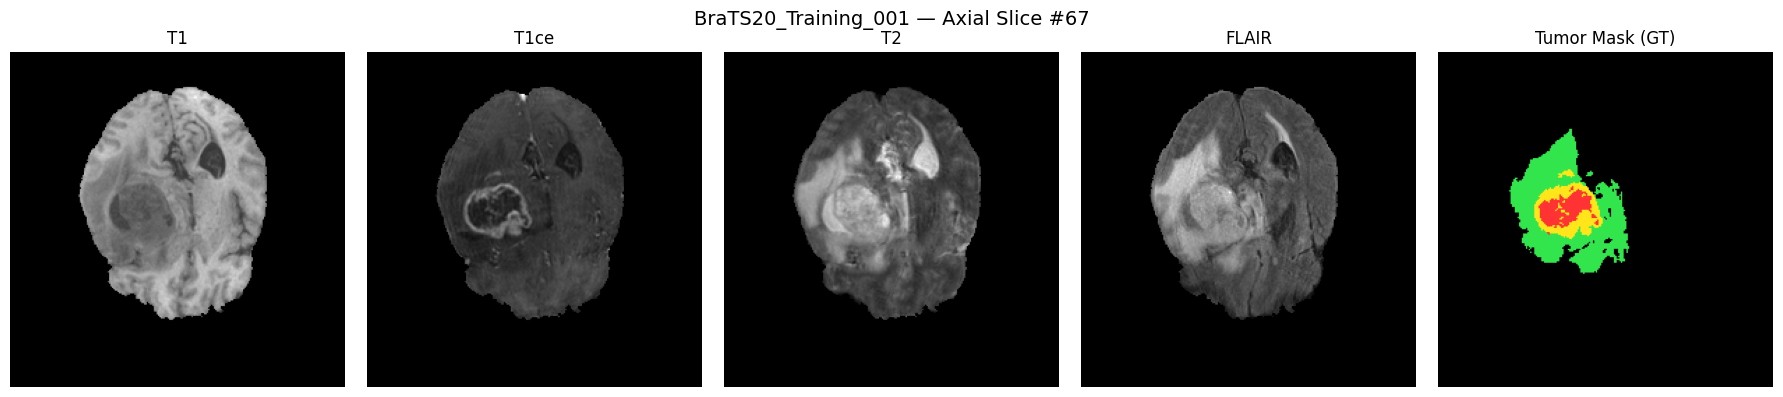

In [5]:
import os
import glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

# 1. Locate the patient folders inside BraTS2020_TrainingData
train_root = os.path.join(dataset_path, 'BraTS2020_TrainingData')
nested_root = os.path.join(train_root, 'MICCAI_BraTS2020_TrainingData')
if os.path.isdir(nested_root):
    train_root = nested_root

# 2. Collect all patients that have all 5 files (t1, t1ce, t2, flair, seg)
patients = []
skipped = []

for folder in sorted(os.listdir(train_root)):
    p_dir = os.path.join(train_root, folder)
    if not os.path.isdir(p_dir):
        continue

    files = {}
    for mod in ['t1', 't1ce', 't2', 'flair', 'seg']:
        matches = glob.glob(os.path.join(p_dir, f'*_{mod}.nii*'))
        if matches:
            files[mod] = matches[0]

    if len(files) == 5:
        files['id'] = folder
        patients.append(files)
    else:
        skipped.append(folder)

print(f"Complete patients ready to use : {len(patients)}")
print(f"Skipped incomplete folders     : {len(skipped)} {skipped}")

# 3. Load the first patient and inspect its 3D properties
sample = patients[0]
t1_img = nib.load(sample['t1'])
t1    = t1_img.get_fdata()
t1ce  = nib.load(sample['t1ce']).get_fdata()
t2    = nib.load(sample['t2']).get_fdata()
flair = nib.load(sample['flair']).get_fdata()
seg   = nib.load(sample['seg']).get_fdata()

print(f"\nSample patient : {sample['id']}")
print(f"3D Volume shape: {t1.shape} (Height x Width x Slices)")
print(f"Voxel spacing  : {t1_img.header.get_zooms()} mm (1:1 millimeter scale)")
print(f"Mask labels    : {np.unique(seg).astype(int)}")

# 4. Find the axial slice with the largest tumor area
best_slice = int(np.argmax((seg > 0).sum(axis=(0, 1))))

# Build color-coded tumor mask (Red=Necrotic Core, Green=Edema, Yellow=Enhancing)
mask_slice = np.rot90(seg[:, :, best_slice])
rgb_mask = np.zeros((*mask_slice.shape, 3))
rgb_mask[mask_slice == 1] = [1.0, 0.2, 0.2]  # Red: Label 1 (Necrotic Core)
rgb_mask[mask_slice == 2] = [0.2, 0.9, 0.3]  # Green: Label 2 (Edema)
rgb_mask[mask_slice == 4] = [1.0, 0.9, 0.1]  # Yellow: Label 4 (Enhancing Tumor)

# 5. Display all 4 MRI modalities + Tumor Mask
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
views = [
    (np.rot90(t1[:, :, best_slice]),    'T1',    'gray'),
    (np.rot90(t1ce[:, :, best_slice]),  'T1ce',  'gray'),
    (np.rot90(t2[:, :, best_slice]),    'T2',    'gray'),
    (np.rot90(flair[:, :, best_slice]), 'FLAIR', 'gray'),
]

for ax, (img, title, cmap) in zip(axes[:4], views):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

axes[4].imshow(rgb_mask)
axes[4].set_title('Tumor Mask (GT)', fontsize=12)
axes[4].axis('off')

plt.suptitle(f"{sample['id']} — Axial Slice #{best_slice}", fontsize=14)
plt.tight_layout()
plt.show()

In [6]:
import json
import random
import torch
from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    ConvertToMultiChannelBasedOnBratsClassesd,
    Orientationd,
    Spacingd,
    CropForegroundd,
    NormalizeIntensityd,
    SpatialPadd,
    RandSpatialCropd,
    RandFlipd,
    RandScaleIntensityd,
    RandShiftIntensityd,
    EnsureTyped,
)

# 1. Format all 368 patients for MONAI: 4 stacked MRI files + 1 label file
data_dicts = [
    {
        "id": p["id"],
        "image": [p["t1"], p["t1ce"], p["t2"], p["flair"]],
        "label": p["seg"],
    }
    for p in patients
]

# 2. Shuffle reproducibly and split 70% Train / 15% Val / 15% Test
rng = random.Random(42)
shuffled = data_dicts.copy()
rng.shuffle(shuffled)

n_total = len(shuffled)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)

train_files = shuffled[:n_train]
val_files   = shuffled[n_train : n_train + n_val]
test_files  = shuffled[n_train + n_val :]

# Save the split to Google Drive so both 3D U-Net & SegResNet use the exact same split
split_path = f"{PROJECT_DIR}/logs/dataset_split.json"
with open(split_path, "w") as f:
    json.dump({"train": train_files, "val": val_files, "test": test_files}, f, indent=2)

print(f"Train patients : {len(train_files)}")
print(f"Val patients   : {len(val_files)}")
print(f"Test patients  : {len(test_files)}")
print(f"Split saved to : {split_path}")

# 3. Build MONAI Training Transforms (with 3D data augmentation)
train_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    ConvertToMultiChannelBasedOnBratsClassesd(keys="label"),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.0, 1.0, 1.0), mode=("bilinear", "nearest")),
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    SpatialPadd(keys=["image", "label"], spatial_size=(128, 128, 128)),
    RandSpatialCropd(keys=["image", "label"], roi_size=(128, 128, 128), random_size=False),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=2),
    RandScaleIntensityd(keys="image", factors=0.1, prob=0.5),
    RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
    EnsureTyped(keys=["image", "label"], dtype=torch.float32),
])

# 4. Build MONAI Validation / Test Transforms (no random augmentations)
val_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    ConvertToMultiChannelBasedOnBratsClassesd(keys="label"),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.0, 1.0, 1.0), mode=("bilinear", "nearest")),
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    EnsureTyped(keys=["image", "label"], dtype=torch.float32),
])

# 5. Create PyTorch DataLoaders
train_ds = Dataset(data=train_files, transform=train_transforms)
val_ds   = Dataset(data=val_files,   transform=val_transforms)
test_ds  = Dataset(data=test_files,  transform=val_transforms)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=1, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

# 6. Sanity test: load 1 real batch and check its tensor shapes
print("\nTesting data pipeline on 1 training batch (takes ~5–10 seconds)...")
batch = next(iter(train_loader))
print("Batch image shape:", tuple(batch["image"].shape), "-> (Batch, 4 MRI channels, 128, 128, 128)")
print("Batch label shape:", tuple(batch["label"].shape), "-> (Batch, 3 Tumor channels: TC/WT/ET, 128, 128, 128)")
print("Step 2 complete! Pipeline is ready for training.")

Train patients : 257
Val patients   : 55
Test patients  : 56
Split saved to : /content/drive/MyDrive/brain-tumor-3d-print/logs/dataset_split.json

Testing data pipeline on 1 training batch (takes ~5–10 seconds)...


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Batch image shape: (2, 4, 128, 128, 128) -> (Batch, 4 MRI channels, 128, 128, 128)
Batch label shape: (2, 3, 128, 128, 128) -> (Batch, 3 Tumor channels: TC/WT/ET, 128, 128, 128)
Step 2 complete! Pipeline is ready for training.


In [7]:
import os
import time
import json
import torch
from monai.networks.nets import UNet, SegResNet
from monai.losses import DiceLoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference
from monai.transforms import Compose, Activations, AsDiscrete
from monai.data import decollate_batch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_model(model_name):
    if model_name == "segresnet":
        return SegResNet(
            spatial_dims=3,
            init_filters=16,
            in_channels=4,
            out_channels=3,
            blocks_down=[1, 2, 2, 4],
            blocks_up=[1, 1, 1],
            dropout_prob=0.2,
        ).to(device)
    elif model_name == "unet":
        return UNet(
            spatial_dims=3,
            in_channels=4,
            out_channels=3,
            channels=(16, 32, 64, 128, 256),
            strides=(2, 2, 2, 2),
            num_res_units=2,
        ).to(device)
    else:
        raise ValueError("Choose 'segresnet' or 'unet'")

def train_model(model_name, run_until_epoch=10, total_planned_epochs=30, val_interval=2, resume=True):
    model = build_model(model_name)
    loss_fn = DiceLoss(to_onehot_y=False, sigmoid=True, squared_pred=True, smooth_nr=0, smooth_dr=1e-5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_planned_epochs)
    scaler = torch.amp.GradScaler("cuda")

    post_trans = Compose([Activations(sigmoid=True), AsDiscrete(threshold=0.5)])
    dice_metric = DiceMetric(include_background=True, reduction="mean_batch")

    best_path = f"{PROJECT_DIR}/weights/{model_name}_best.pth"
    last_path = f"{PROJECT_DIR}/weights/{model_name}_last.pth"
    hist_path = f"{PROJECT_DIR}/logs/{model_name}_history.json"

    start_epoch = 1
    best_dice = 0.0
    history = {"epoch": [], "train_loss": [], "val_mean_dice": [], "val_tc": [], "val_wt": [], "val_et": []}

    # Auto-resume from Google Drive if a previous checkpoint exists
    if resume and os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        start_epoch = ckpt["epoch"] + 1
        best_dice = ckpt["best_dice"]
        history = ckpt["history"]
        print(f"Resumed {model_name.upper()} from epoch {ckpt['epoch']} (Best Mean Dice so far: {best_dice:.4f})")
    else:
        print(f"Starting fresh training for {model_name.upper()} on {device}...")

    if start_epoch > run_until_epoch:
        print(f"{model_name.upper()} already reached epoch {start_epoch - 1}. Increase run_until_epoch to train further.")
        return model, history

    for epoch in range(start_epoch, run_until_epoch + 1):
        t0 = time.time()
        model.train()
        epoch_loss = 0.0

        for step, batch in enumerate(train_loader, start=1):
            inputs = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda"):
                outputs = model(inputs)
                loss = loss_fn(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            epoch_loss += loss.item()
            if step % 30 == 0 or step == len(train_loader):
                print(f"  Epoch {epoch}/{run_until_epoch} | Batch {step}/{len(train_loader)} | Loss: {loss.item():.4f}")

        scheduler.step()
        avg_loss = epoch_loss / len(train_loader)
        elapsed = time.time() - t0
        print(f"-> Epoch {epoch} finished in {elapsed:.0f}s | Avg Train Loss: {avg_loss:.4f}")

        # Run validation every `val_interval` epochs (and on the final epoch)
        if epoch % val_interval == 0 or epoch == run_until_epoch:
            model.eval()
            with torch.no_grad():
                for val_batch in val_loader:
                    val_inputs = val_batch["image"].to(device, non_blocking=True)
                    val_labels = val_batch["label"].to(device, non_blocking=True)
                    with torch.amp.autocast("cuda"):
                        val_outputs = sliding_window_inference(
                            val_inputs, roi_size=(128, 128, 128), sw_batch_size=2, predictor=model, overlap=0.25
                        )
                    val_outputs = [post_trans(i) for i in decollate_batch(val_outputs)]
                    val_labels = decollate_batch(val_labels)
                    dice_metric(y_pred=val_outputs, y=val_labels)

                scores = dice_metric.aggregate()
                tc, wt, et = scores[0].item(), scores[1].item(), scores[2].item()
                mean_dice = (tc + wt + et) / 3.0
                dice_metric.reset()

            print(f"   [VAL] Mean Dice: {mean_dice:.4f} | WT: {wt:.4f} | TC: {tc:.4f} | ET: {et:.4f}")

            history["epoch"].append(epoch)
            history["train_loss"].append(round(avg_loss, 4))
            history["val_mean_dice"].append(round(mean_dice, 4))
            history["val_tc"].append(round(tc, 4))
            history["val_wt"].append(round(wt, 4))
            history["val_et"].append(round(et, 4))

            if mean_dice > best_dice:
                best_dice = mean_dice
                torch.save(model.state_dict(), best_path)
                print(f"   *** New BEST {model_name.upper()} saved to Drive! (Mean Dice: {best_dice:.4f}) ***")

        # Save resume checkpoint and training log to Google Drive after every epoch
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "best_dice": best_dice,
            "history": history,
        }, last_path)

        with open(hist_path, "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nDone! Best {model_name.upper()} Mean Dice: {best_dice:.4f}")
    return model, history

print("Training engine ready!")

Training engine ready!


In [ ]:
segresnet_model, segresnet_history = train_model(
    model_name="segresnet",
    run_until_epoch=10,
    total_planned_epochs=30,
    val_interval=2,
    resume=True,
)

Starting fresh training for SEGRESNET on cuda...
  Epoch 1/10 | Batch 30/129 | Loss: 0.8618
  Epoch 1/10 | Batch 60/129 | Loss: 0.8182
  Epoch 1/10 | Batch 90/129 | Loss: 0.8619
  Epoch 1/10 | Batch 120/129 | Loss: 0.8357
  Epoch 1/10 | Batch 129/129 | Loss: 0.7989
-> Epoch 1 finished in 432s | Avg Train Loss: 0.8286
  Epoch 2/10 | Batch 30/129 | Loss: 0.7558
  Epoch 2/10 | Batch 60/129 | Loss: 0.7651
  Epoch 2/10 | Batch 90/129 | Loss: 0.9245
  Epoch 2/10 | Batch 120/129 | Loss: 0.8622
  Epoch 2/10 | Batch 129/129 | Loss: 0.7703
-> Epoch 2 finished in 400s | Avg Train Loss: 0.8021


In [1]:
!pip install -q monai nibabel trimesh einops pyyaml kagglehub

import os, time, json
import numpy as np
import torch
import kagglehub
from google.colab import drive
from monai.data import PersistentDataset, DataLoader, decollate_batch
from monai.networks.nets import UNet, SegResNet
from monai.losses import DiceLoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd,
    ConvertToMultiChannelBasedOnBratsClassesd, Orientationd,
    CropForegroundd, NormalizeIntensityd, SpatialPadd, CastToTyped,
    RandSpatialCropd, RandFlipd, RandScaleIntensityd, RandShiftIntensityd,
    EnsureTyped, Activations, AsDiscrete,
)

# 1. Re-connect Drive & check GPU
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/brain-tumor-3d-print'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert torch.cuda.is_available(), "GPU is off! Go to Runtime -> Change runtime type -> T4 GPU, then re-run."
print("GPU ready:", torch.cuda.get_device_name(0))

# 2. Ensure BraTS dataset is mounted & load your exact saved patient split
dataset_path = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
with open(f"{PROJECT_DIR}/logs/dataset_split.json") as f:
    splits = json.load(f)
train_files, val_files, test_files = splits["train"], splits["val"], splits["test"]

# 3. Set up FAST SSD-cached DataLoaders (cuts epoch time from ~7 min to ~1 min)
CACHE_DIR = "/content/monai_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

train_transforms_fast = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    ConvertToMultiChannelBasedOnBratsClassesd(keys="label"),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    SpatialPadd(keys=["image", "label"], spatial_size=(128, 128, 128)),
    CastToTyped(keys=["image", "label"], dtype=(np.float16, np.uint8)),
    RandSpatialCropd(keys=["image", "label"], roi_size=(128, 128, 128), random_size=False),
    EnsureTyped(keys=["image", "label"], dtype=torch.float32),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=2),
    RandScaleIntensityd(keys="image", factors=0.1, prob=0.5),
    RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
])

val_transforms_fast = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    ConvertToMultiChannelBasedOnBratsClassesd(keys="label"),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    EnsureTyped(keys=["image", "label"], dtype=torch.float32),
])

train_ds = PersistentDataset(data=train_files, transform=train_transforms_fast, cache_dir=f"{CACHE_DIR}/train")
val_ds   = PersistentDataset(data=val_files,   transform=val_transforms_fast,   cache_dir=f"{CACHE_DIR}/val")
test_ds  = PersistentDataset(data=test_files,  transform=val_transforms_fast,   cache_dir=f"{CACHE_DIR}/test")

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=1, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

# 4. Restore the training engine
def build_model(model_name):
    if model_name == "segresnet":
        return SegResNet(
            spatial_dims=3, init_filters=16, in_channels=4, out_channels=3,
            blocks_down=[1, 2, 2, 4], blocks_up=[1, 1, 1], dropout_prob=0.2
        ).to(device)
    elif model_name == "unet":
        return UNet(
            spatial_dims=3, in_channels=4, out_channels=3,
            channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2
        ).to(device)
    raise ValueError("Choose 'segresnet' or 'unet'")

def train_model(model_name, run_until_epoch=10, total_planned_epochs=30, val_interval=2, resume=True):
    model = build_model(model_name)
    loss_fn = DiceLoss(to_onehot_y=False, sigmoid=True, squared_pred=True, smooth_nr=0, smooth_dr=1e-5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_planned_epochs)
    scaler = torch.amp.GradScaler("cuda")
    post_trans = Compose([Activations(sigmoid=True), AsDiscrete(threshold=0.5)])
    dice_metric = DiceMetric(include_background=True, reduction="mean_batch")

    best_path = f"{PROJECT_DIR}/weights/{model_name}_best.pth"
    last_path = f"{PROJECT_DIR}/weights/{model_name}_last.pth"
    hist_path = f"{PROJECT_DIR}/logs/{model_name}_history.json"

    start_epoch, best_dice = 1, 0.0
    history = {"epoch": [], "train_loss": [], "val_mean_dice": [], "val_tc": [], "val_wt": [], "val_et": []}

    if resume and os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        start_epoch = ckpt["epoch"] + 1
        best_dice = ckpt["best_dice"]
        history = ckpt["history"]
        print(f"Resumed {model_name.upper()} from epoch {ckpt['epoch']} (Best Mean Dice so far: {best_dice:.4f})")
    else:
        print(f"Starting fresh training for {model_name.upper()} on {device}...")

    if start_epoch > run_until_epoch:
        print(f"{model_name.upper()} already reached epoch {start_epoch - 1}.")
        return model, history

    for epoch in range(start_epoch, run_until_epoch + 1):
        t0 = time.time()
        model.train()
        epoch_loss = 0.0
        for step, batch in enumerate(train_loader, start=1):
            inputs = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda"):
                loss = loss_fn(model(inputs), labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_loss += loss.item()
            if step % 30 == 0 or step == len(train_loader):
                print(f"  Epoch {epoch}/{run_until_epoch} | Batch {step}/{len(train_loader)} | Loss: {loss.item():.4f}")

        scheduler.step()
        avg_loss = epoch_loss / len(train_loader)
        print(f"-> Epoch {epoch} finished in {time.time() - t0:.0f}s | Avg Train Loss: {avg_loss:.4f}")

        if epoch % val_interval == 0 or epoch == run_until_epoch:
            model.eval()
            with torch.no_grad():
                for val_batch in val_loader:
                    val_inputs = val_batch["image"].to(device, non_blocking=True)
                    val_labels = val_batch["label"].to(device, non_blocking=True)
                    with torch.amp.autocast("cuda"):
                        val_outputs = sliding_window_inference(
                            val_inputs, roi_size=(128, 128, 128), sw_batch_size=2, predictor=model, overlap=0.25
                        )
                    dice_metric(y_pred=[post_trans(i) for i in decollate_batch(val_outputs)], y=decollate_batch(val_labels))
                scores = dice_metric.aggregate()
                tc, wt, et = scores[0].item(), scores[1].item(), scores[2].item()
                mean_dice = (tc + wt + et) / 3.0
                dice_metric.reset()

            print(f"   [VAL] Mean Dice: {mean_dice:.4f} | WT: {wt:.4f} | TC: {tc:.4f} | ET: {et:.4f}")
            history["epoch"].append(epoch)
            history["train_loss"].append(round(avg_loss, 4))
            history["val_mean_dice"].append(round(mean_dice, 4))
            history["val_tc"].append(round(tc, 4))
            history["val_wt"].append(round(wt, 4))
            history["val_et"].append(round(et, 4))

            if mean_dice > best_dice:
                best_dice = mean_dice
                torch.save(model.state_dict(), best_path)
                print(f"   *** New BEST {model_name.upper()} saved to Drive! (Mean Dice: {best_dice:.4f}) ***")

        torch.save({
            "epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "best_dice": best_dice, "history": history,
        }, last_path)
        with open(hist_path, "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nDone! Best {model_name.upper()} Mean Dice: {best_dice:.4f}")
    return model, history

print("All set! Fast caching + resume engine ready.")

Mounted at /content/drive
GPU ready: Tesla T4
Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
All set! Fast caching + resume engine ready.


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [2]:
segresnet_model, segresnet_history = train_model(
    model_name="segresnet",
    run_until_epoch=10,
    total_planned_epochs=30,
    val_interval=2,
    resume=True,
)

Resumed SEGRESNET from epoch 3 (Best Mean Dice so far: 0.2648)
  Epoch 4/10 | Batch 30/129 | Loss: 0.6709
  Epoch 4/10 | Batch 60/129 | Loss: 0.7205
  Epoch 4/10 | Batch 90/129 | Loss: 0.7667
  Epoch 4/10 | Batch 120/129 | Loss: 0.7804
  Epoch 4/10 | Batch 129/129 | Loss: 0.8355
-> Epoch 4 finished in 428s | Avg Train Loss: 0.7666
   [VAL] Mean Dice: 0.2762 | WT: 0.7905 | TC: 0.0242 | ET: 0.0139
   *** New BEST SEGRESNET saved to Drive! (Mean Dice: 0.2762) ***
  Epoch 5/10 | Batch 30/129 | Loss: 0.6845
  Epoch 5/10 | Batch 60/129 | Loss: 0.8305
  Epoch 5/10 | Batch 90/129 | Loss: 0.6634
  Epoch 5/10 | Batch 120/129 | Loss: 0.8283
  Epoch 5/10 | Batch 129/129 | Loss: 0.8953
-> Epoch 5 finished in 87s | Avg Train Loss: 0.7477
  Epoch 6/10 | Batch 30/129 | Loss: 0.7058
  Epoch 6/10 | Batch 60/129 | Loss: 0.7268
  Epoch 6/10 | Batch 90/129 | Loss: 0.7922
  Epoch 6/10 | Batch 120/129 | Loss: 0.6828
  Epoch 6/10 | Batch 129/129 | Loss: 0.5641
-> Epoch 6 finished in 85s | Avg Train Loss: 0.73

In [3]:
segresnet_model, segresnet_history = train_model(
    model_name="segresnet",
    run_until_epoch=30,
    total_planned_epochs=30,
    val_interval=5,
    resume=True,
)

Resumed SEGRESNET from epoch 10 (Best Mean Dice so far: 0.5196)
  Epoch 11/30 | Batch 30/129 | Loss: 0.6992
  Epoch 11/30 | Batch 60/129 | Loss: 0.6160
  Epoch 11/30 | Batch 90/129 | Loss: 0.6330
  Epoch 11/30 | Batch 120/129 | Loss: 0.5998
  Epoch 11/30 | Batch 129/129 | Loss: 0.7263
-> Epoch 11 finished in 85s | Avg Train Loss: 0.6472
  Epoch 12/30 | Batch 30/129 | Loss: 0.6270
  Epoch 12/30 | Batch 60/129 | Loss: 0.7359
  Epoch 12/30 | Batch 90/129 | Loss: 0.5630
  Epoch 12/30 | Batch 120/129 | Loss: 0.6174
  Epoch 12/30 | Batch 129/129 | Loss: 0.4667
-> Epoch 12 finished in 86s | Avg Train Loss: 0.6363
  Epoch 13/30 | Batch 30/129 | Loss: 0.5699
  Epoch 13/30 | Batch 60/129 | Loss: 0.7668
  Epoch 13/30 | Batch 90/129 | Loss: 0.7320
  Epoch 13/30 | Batch 120/129 | Loss: 0.6808
  Epoch 13/30 | Batch 129/129 | Loss: 0.6408
-> Epoch 13 finished in 85s | Avg Train Loss: 0.6133
  Epoch 14/30 | Batch 30/129 | Loss: 0.5877
  Epoch 14/30 | Batch 60/129 | Loss: 0.5062
  Epoch 14/30 | Batch 9

In [2]:
unet_model, unet_history = train_model(
    model_name="unet",
    run_until_epoch=30,
    total_planned_epochs=30,
    val_interval=5,
    resume=True,
)

Resumed UNET from epoch 15 (Best Mean Dice so far: 0.4143)
  Epoch 16/30 | Batch 30/129 | Loss: 0.5416
  Epoch 16/30 | Batch 60/129 | Loss: 0.6286
  Epoch 16/30 | Batch 90/129 | Loss: 0.8451
  Epoch 16/30 | Batch 120/129 | Loss: 0.7711
  Epoch 16/30 | Batch 129/129 | Loss: 0.4297
-> Epoch 16 finished in 388s | Avg Train Loss: 0.6409
  Epoch 17/30 | Batch 30/129 | Loss: 0.6879
  Epoch 17/30 | Batch 60/129 | Loss: 0.4357
  Epoch 17/30 | Batch 90/129 | Loss: 0.8029
  Epoch 17/30 | Batch 120/129 | Loss: 0.4849
  Epoch 17/30 | Batch 129/129 | Loss: 0.8204
-> Epoch 17 finished in 59s | Avg Train Loss: 0.6306
  Epoch 18/30 | Batch 30/129 | Loss: 0.7997
  Epoch 18/30 | Batch 60/129 | Loss: 0.5156
  Epoch 18/30 | Batch 90/129 | Loss: 0.8102
  Epoch 18/30 | Batch 120/129 | Loss: 0.8059
  Epoch 18/30 | Batch 129/129 | Loss: 0.6194
-> Epoch 18 finished in 58s | Avg Train Loss: 0.6241
  Epoch 19/30 | Batch 30/129 | Loss: 0.6753
  Epoch 19/30 | Batch 60/129 | Loss: 0.4128
  Epoch 19/30 | Batch 90/12


Evaluating SEGRESNET on 56 unseen test patients...
  Processed 15/56 test patients...
  Processed 30/56 test patients...
  Processed 45/56 test patients...
  Processed 56/56 test patients...

Evaluating UNET on 56 unseen test patients...
  Processed 15/56 test patients...
  Processed 30/56 test patients...
  Processed 45/56 test patients...
  Processed 56/56 test patients...

================ OFFICIAL TEST SET BENCHMARK ================
    Model  Dice WT  Dice TC  Dice ET  Mean Dice  HD95 WT (mm)  HD95 TC (mm)  HD95 ET (mm)  Mean HD95 (mm)  Avg Inference (s/patient)
SegResNet   0.8911   0.7366   0.6257     0.7511         11.26         12.07          9.83           11.05                       0.68
 3D U-Net   0.7551   0.4367   0.2504     0.4808         16.15         28.43         29.78           24.79                       0.14

Saved benchmark table to: /content/drive/MyDrive/brain-tumor-3d-print/exports/benchmark_results.csv


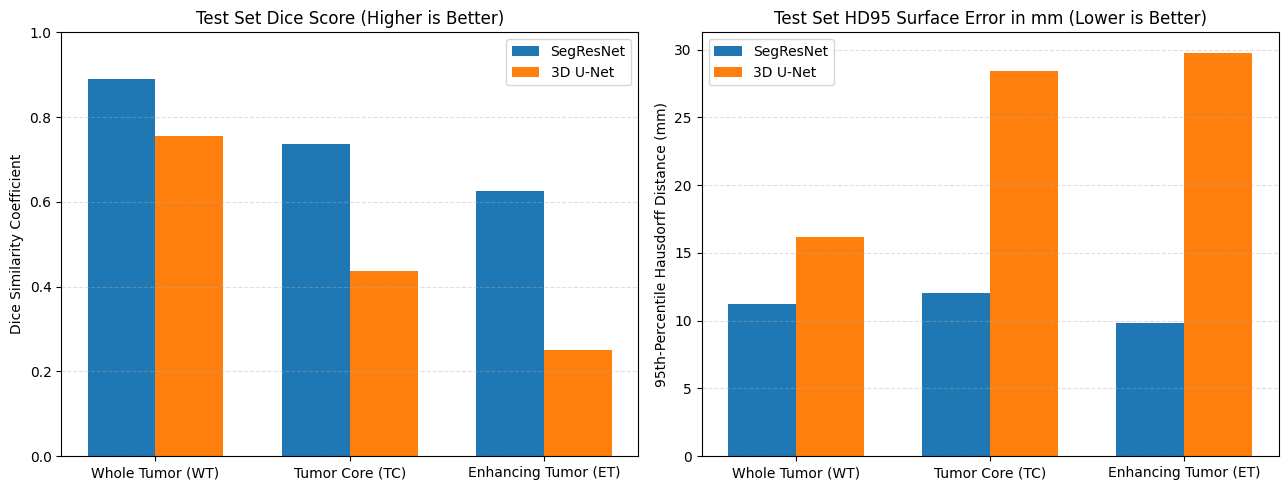

Saved high-res chart to: /content/drive/MyDrive/brain-tumor-3d-print/exports/model_comparison.png


In [3]:
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from monai.inferers import sliding_window_inference
from monai.metrics import compute_dice, compute_hausdorff_distance

warnings.filterwarnings("ignore")

def evaluate_on_test(model_name):
    model = build_model(model_name)
    weights_path = f"{PROJECT_DIR}/weights/{model_name}_best.pth"
    model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
    model.eval()

    dice_list, hd95_list, times = [], [], []
    print(f"\nEvaluating {model_name.upper()} on {len(test_loader)} unseen test patients...")

    with torch.no_grad():
        for idx, batch in enumerate(test_loader, start=1):
            inputs = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            torch.cuda.synchronize()
            t0 = time.time()
            with torch.amp.autocast("cuda"):
                outputs = sliding_window_inference(
                    inputs, roi_size=(128, 128, 128), sw_batch_size=2, predictor=model, overlap=0.5
                )
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            torch.cuda.synchronize()
            times.append(time.time() - t0)

            # Channel order from BraTS transform: [0]=TC, [1]=WT, [2]=ET
            d = compute_dice(y_pred=preds, y=labels, include_background=True, ignore_empty=True)
            h = compute_hausdorff_distance(
                y_pred=preds, y=labels, include_background=True, percentile=95, spacing=(1.0, 1.0, 1.0)
            )
            dice_list.append(d.cpu().numpy()[0])
            hd95_list.append(h.cpu().numpy()[0])

            if idx % 15 == 0 or idx == len(test_loader):
                print(f"  Processed {idx}/{len(test_loader)} test patients...")

    dice_arr = np.array(dice_list)  # shape: (56, 3) -> TC, WT, ET
    hd95_arr = np.array(hd95_list)

    def safe_mean(col):
        valid = col[np.isfinite(col)]
        return float(np.mean(valid)) if len(valid) > 0 else float("nan")

    tc_d, wt_d, et_d = safe_mean(dice_arr[:, 0]), safe_mean(dice_arr[:, 1]), safe_mean(dice_arr[:, 2])
    tc_h, wt_h, et_h = safe_mean(hd95_arr[:, 0]), safe_mean(hd95_arr[:, 1]), safe_mean(hd95_arr[:, 2])

    return {
        "Model": "SegResNet" if model_name == "segresnet" else "3D U-Net",
        "Dice WT": round(wt_d, 4),
        "Dice TC": round(tc_d, 4),
        "Dice ET": round(et_d, 4),
        "Mean Dice": round((wt_d + tc_d + et_d) / 3.0, 4),
        "HD95 WT (mm)": round(wt_h, 2),
        "HD95 TC (mm)": round(tc_h, 2),
        "HD95 ET (mm)": round(et_h, 2),
        "Mean HD95 (mm)": round((wt_h + tc_h + et_h) / 3.0, 2),
        "Avg Inference (s/patient)": round(float(np.mean(times)), 2),
    }

# 1. Benchmark both models on the held-out test set
results = [evaluate_on_test("segresnet"), evaluate_on_test("unet")]
df = pd.DataFrame(results)

csv_path = f"{PROJECT_DIR}/exports/benchmark_results.csv"
df.to_csv(csv_path, index=False)

print("\n================ OFFICIAL TEST SET BENCHMARK ================")
print(df.to_string(index=False))
print(f"\nSaved benchmark table to: {csv_path}")

# 2. Plot thesis-ready comparison charts (Test Dice + Test HD95)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
classes = ["Whole Tumor (WT)", "Tumor Core (TC)", "Enhancing Tumor (ET)"]
x = np.arange(len(classes))
width = 0.35

seg_dice = [df.loc[0, "Dice WT"], df.loc[0, "Dice TC"], df.loc[0, "Dice ET"]]
unet_dice = [df.loc[1, "Dice WT"], df.loc[1, "Dice TC"], df.loc[1, "Dice ET"]]

axes[0].bar(x - width/2, seg_dice, width, label="SegResNet", color="#1f77b4")
axes[0].bar(x + width/2, unet_dice, width, label="3D U-Net", color="#ff7f0e")
axes[0].set_title("Test Set Dice Score (Higher is Better)", fontsize=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(classes)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Dice Similarity Coefficient")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

seg_hd = [df.loc[0, "HD95 WT (mm)"], df.loc[0, "HD95 TC (mm)"], df.loc[0, "HD95 ET (mm)"]]
unet_hd = [df.loc[1, "HD95 WT (mm)"], df.loc[1, "HD95 TC (mm)"], df.loc[1, "HD95 ET (mm)"]]

axes[1].bar(x - width/2, seg_hd, width, label="SegResNet", color="#1f77b4")
axes[1].bar(x + width/2, unet_hd, width, label="3D U-Net", color="#ff7f0e")
axes[1].set_title("Test Set HD95 Surface Error in mm (Lower is Better)", fontsize=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(classes)
axes[1].set_ylabel("95th-Percentile Hausdorff Distance (mm)")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
chart_path = f"{PROJECT_DIR}/exports/model_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()
print(f"Saved high-res chart to: {chart_path}")

In [4]:
import os
import time
import json
import numpy as np
import nibabel as nib
import torch
import trimesh
import plotly.graph_objects as go
from scipy import ndimage
from scipy.spatial import ConvexHull
from scipy.spatial.distance import pdist
from skimage.measure import marching_cubes
from monai.inferers import sliding_window_inference
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd,
    Orientationd, Spacingd, NormalizeIntensityd, EnsureTyped,
)

# 1. Load your winning SegResNet weights
seg_model = build_model("segresnet")
seg_model.load_state_dict(
    torch.load(f"{PROJECT_DIR}/weights/segresnet_best.pth", map_location=device, weights_only=True)
)
seg_model.eval()

# 2. Pick a great unseen test patient for 3D printing (well-defined tumor between 40–100 cm³)
chosen_patient = test_files[0]
for p in test_files[:20]:
    gt = nib.load(p["label"]).get_fdata()
    vol_cm3 = (gt > 0).sum() / 1000.0
    if 40.0 <= vol_cm3 <= 100.0:
        chosen_patient = p
        break

patient_id = chosen_patient["id"]
print(f"Selected unseen test patient for 3D printing: {patient_id}")

# --- START END-TO-END TIMER ---
t_start = time.time()

# 3. Load and align all 4 MRI modalities to 1x1x1 mm RAS space (NO cropping so brain & tumor stay aligned)
load_align = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Orientationd(keys=["image"], axcodes="RAS"),
    Spacingd(keys=["image"], pixdim=(1.0, 1.0, 1.0), mode="bilinear"),
])
norm_only = Compose([
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    EnsureTyped(keys="image", dtype=torch.float32),
])

aligned = load_align({"image": chosen_patient["image"]})
t1_aligned = aligned["image"][0].numpy()  # Raw aligned T1 for brain shell extraction
input_tensor = norm_only(aligned)["image"].unsqueeze(0).to(device)  # Shape: (1, 4, 240, 240, 155)

# 4. Run full-volume 3D segmentation with SegResNet
torch.cuda.synchronize()
t_inf0 = time.time()
with torch.no_grad(), torch.amp.autocast("cuda"):
    logits = sliding_window_inference(
        input_tensor, roi_size=(128, 128, 128), sw_batch_size=2, predictor=seg_model, overlap=0.5
    )
    preds = (torch.sigmoid(logits) >= 0.5).cpu().numpy()[0].astype(bool)  # [0]=TC, [1]=WT, [2]=ET
torch.cuda.synchronize()
inf_time = time.time() - t_inf0

tc_mask, wt_mask, et_mask = preds[0], preds[1], preds[2]

# 5. Helper: keep largest solid 3D component so no stray floating voxels break the 3D print
def keep_largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (np.argmax(sizes) + 1))

# Clean tumor mask (Whole Tumor) and brain parenchyma mask
tumor_clean = ndimage.binary_fill_holes(ndimage.binary_closing(keep_largest_component(wt_mask), iterations=2))
brain_clean = ndimage.binary_fill_holes(ndimage.binary_closing(keep_largest_component(t1_aligned > 0), iterations=2))

# 6. Helper: extract clinical volumetric metrics (cm³ volume, bounding box mm, max 3D diameter mm)
def compute_clinical_metrics(mask):
    n_vox = int(mask.sum())
    if n_vox < 10:
        return {"volume_cm3": 0.0, "bbox_mm": [0.0, 0.0, 0.0], "max_diameter_mm": 0.0}
    vol_cm3 = n_vox / 1000.0  # 1x1x1 mm voxel = 0.001 cm³
    coords = np.argwhere(mask)
    dims = (coords.max(axis=0) - coords.min(axis=0) + 1).astype(float)
    verts, _, _, _ = marching_cubes(np.pad(mask, 1).astype(np.float32), level=0.5, spacing=(1.0, 1.0, 1.0))
    hull = ConvexHull(verts)
    max_diam = float(pdist(verts[hull.vertices]).max())
    return {
        "volume_cm3": round(vol_cm3, 2),
        "bbox_mm": [round(float(d), 2) for d in dims],
        "max_diameter_mm": round(max_diam, 2),
    }

metrics = {
    "Whole_Tumor_WT": compute_clinical_metrics(tumor_clean),
    "Tumor_Core_TC": compute_clinical_metrics(tc_mask),
    "Enhancing_Tumor_ET": compute_clinical_metrics(et_mask),
}

# 7. Engineer the 3D-printable Brain Cutaway with 1 mm clearance & zero-undercut vertical pull-out
b_coords = np.argwhere(brain_clean)
t_coords = np.argwhere(tumor_clean)
bx, by, bz = b_coords.mean(axis=0)
cx, cy, cz = t_coords.mean(axis=0).astype(int)

X, Y, Z = np.indices(brain_clean.shape)
brain_cutaway = brain_clean.copy()

# Cut away the superior section (Z > cz) on the tumor's hemisphere, keeping the opposite hemisphere intact
if cx >= bx:
    cut_x = max(0, int(t_coords[:, 0].min()) - 8)
    brain_cutaway[(Z > cz) & (X >= cut_x)] = False
else:
    cut_x = min(brain_clean.shape[0] - 1, int(t_coords[:, 0].max()) + 8)
    brain_cutaway[(Z > cz) & (X <= cut_x)] = False

# Dilate tumor by 1 voxel (~1 mm radial clearance) & sweep upward in +Z so the tumor lifts straight out
struct = ndimage.generate_binary_structure(3, 1)
tumor_dilated = ndimage.binary_dilation(tumor_clean, structure=struct, iterations=1)
cavity_sweep = np.maximum.accumulate(tumor_dilated, axis=2)  # Eliminates vertical overhangs/undercuts
brain_cutaway = keep_largest_component(brain_cutaway & (~cavity_sweep))

# 8. Helper: Marching Cubes + Volume-Preserving Taubin Smoothing + Watertight Repair
def mask_to_watertight_stl(mask, smooth_iters=15):
    padded = np.pad(mask.astype(np.float32), pad_width=1, mode="constant", constant_values=0)
    verts, faces, _, _ = marching_cubes(padded, level=0.5, spacing=(1.0, 1.0, 1.0))
    mesh = trimesh.Trimesh(vertices=verts, faces=faces, process=True)
    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_before = abs(mesh.volume) / 1000.0
    trimesh.smoothing.filter_taubin(mesh, lamb=0.5, nu=-0.53, iterations=smooth_iters)
    trimesh.repair.fill_holes(mesh)
    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_after = abs(mesh.volume) / 1000.0
    drift_pct = abs(vol_after - vol_before) / max(vol_before, 1e-6) * 100.0
    return mesh, round(vol_before, 2), round(vol_after, 2), round(drift_pct, 2)

print("Generating watertight 1:1 scale meshes with Taubin smoothing...")
tumor_mesh, t_v0, t_v1, t_drift = mask_to_watertight_stl(tumor_clean, smooth_iters=15)
brain_mesh, b_v0, b_v1, b_drift = mask_to_watertight_stl(brain_cutaway, smooth_iters=12)

# 9. Save STL files & Clinical Report to Google Drive
out_dir = f"{PROJECT_DIR}/exports/{patient_id}"
os.makedirs(out_dir, exist_ok=True)

tumor_stl_path = f"{out_dir}/tumor.stl"
brain_stl_path = f"{out_dir}/brain_cutaway.stl"
report_path    = f"{out_dir}/clinical_report.json"

tumor_mesh.export(tumor_stl_path)
brain_mesh.export(brain_stl_path)

total_time = time.time() - t_start

report = {
    "patient_id": patient_id,
    "model": "SegResNet",
    "timing_seconds": {
        "ai_segmentation": round(inf_time, 2),
        "total_end_to_end": round(total_time, 2),
    },
    "clinical_metrics": metrics,
    "mesh_quality": {
        "tumor_watertight": bool(tumor_mesh.is_watertight),
        "tumor_bbox_stl_mm": [round(float(x), 2) for x in tumor_mesh.extents],
        "tumor_volume_before_taubin_cm3": t_v0,
        "tumor_volume_after_taubin_cm3": t_v1,
        "tumor_volume_drift_pct": t_drift,
        "brain_watertight": bool(brain_mesh.is_watertight),
        "brain_bbox_stl_mm": [round(float(x), 2) for x in brain_mesh.extents],
        "brain_volume_drift_pct": b_drift,
    },
}
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n================ CLINICAL & 3D MESH REPORT ================")
print(f"Patient ID              : {patient_id}")
print(f"AI Inference Time       : {inf_time:.2f} s")
print(f"Total End-to-End Time   : {total_time:.2f} s (Target: < 60s)")
print(f"Whole Tumor Volume      : {metrics['Whole_Tumor_WT']['volume_cm3']} cm³")
print(f"Tumor Max 3D Diameter   : {metrics['Whole_Tumor_WT']['max_diameter_mm']} mm")
print(f"Tumor STL Box (X×Y×Z)   : {report['mesh_quality']['tumor_bbox_stl_mm']} mm  <-- Measure with calipers!")
print(f"Tumor Watertight?       : {tumor_mesh.is_watertight} (Taubin volume drift: {t_drift}%)")
print(f"Brain Cutaway Watertight: {brain_mesh.is_watertight} (Taubin volume drift: {b_drift}%)")
print(f"Saved STLs to Drive     : {out_dir}")

# 10. Interactive 3D Preview inside Colab (lightweight step_size=2 for smooth browser rotation)
bv, bf, _, _ = marching_cubes(np.pad(brain_cutaway, 1).astype(np.float32), level=0.5, step_size=2)
tv, tf, _, _ = marching_cubes(np.pad(tumor_clean, 1).astype(np.float32), level=0.5, step_size=2)

fig = go.Figure(data=[
    go.Mesh3d(
        x=bv[:, 0], y=bv[:, 1], z=bv[:, 2],
        i=bf[:, 0], j=bf[:, 1], k=bf[:, 2],
        color="lightgray", opacity=0.45, name="Brain Cutaway",
        lighting=dict(ambient=0.5, diffuse=0.8),
    ),
    go.Mesh3d(
        x=tv[:, 0], y=tv[:, 1], z=tv[:, 2],
        i=tf[:, 0], j=tf[:, 1], k=tf[:, 2],
        color="crimson", opacity=1.0, name="Removable Tumor",
        lighting=dict(ambient=0.4, diffuse=0.9),
    ),
])
fig.update_layout(
    title=f"Interactive 3D Preview — {patient_id} (Drag to rotate, scroll to zoom)",
    scene=dict(aspectmode="data"),
    width=800, height=550,
    margin=dict(l=0, r=0, b=0, t=40),
)
fig.show()

Selected unseen test patient for 3D printing: BraTS20_Training_283
Generating watertight 1:1 scale meshes with Taubin smoothing...

================ CLINICAL & 3D MESH REPORT ================
Patient ID              : BraTS20_Training_283
AI Inference Time       : 1.61 s
Total End-to-End Time   : 14.10 s (Target: < 60s)
Whole Tumor Volume      : 46.86 cm³
Tumor Max 3D Diameter   : 60.74 mm
Tumor STL Box (X×Y×Z)   : [41.37, 48.67, 54.29] mm  <-- Measure with calipers!
Tumor Watertight?       : True (Taubin volume drift: 2.28%)
Brain Cutaway Watertight: False (Taubin volume drift: 0.05%)
Saved STLs to Drive     : /content/drive/MyDrive/brain-tumor-3d-print/exports/BraTS20_Training_283


In [5]:
import json
import numpy as np
import trimesh
from scipy import ndimage
from skimage.measure import marching_cubes

def mask_to_watertight_stl_v2(mask, sigma=0.75, smooth_iters=10):
    # Pad generously so the smooth surface never clips the array boundary
    padded = np.pad(mask.astype(np.float32), pad_width=4, mode="constant", constant_values=0.0)
    # Tiny sub-mm blur removes diagonal voxel pinch-points (guarantees manifold surface)
    field = ndimage.gaussian_filter(padded, sigma=sigma)

    verts, faces, _, _ = marching_cubes(field, level=0.5, spacing=(1.0, 1.0, 1.0))
    mesh = trimesh.Trimesh(vertices=verts, faces=faces, process=True)

    # Keep only the single main solid body (drops any tiny stray surface shells)
    parts = mesh.split(only_watertight=False)
    if len(parts) > 1:
        mesh = max(parts, key=lambda m: len(m.faces))

    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_before = abs(mesh.volume) / 1000.0
    trimesh.smoothing.filter_taubin(mesh, lamb=0.5, nu=-0.52, iterations=smooth_iters)
    trimesh.repair.fill_holes(mesh)
    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_after = abs(mesh.volume) / 1000.0
    drift_pct = abs(vol_after - vol_before) / max(vol_before, 1e-6) * 100.0
    return mesh, round(vol_before, 2), round(vol_after, 2), round(drift_pct, 2)

# Re-generate both STL files cleanly and overwrite Drive exports
tumor_mesh, t_v0, t_v1, t_drift = mask_to_watertight_stl_v2(tumor_clean, sigma=0.75, smooth_iters=10)
brain_mesh, b_v0, b_v1, b_drift = mask_to_watertight_stl_v2(brain_cutaway, sigma=0.75, smooth_iters=10)

tumor_mesh.export(tumor_stl_path)
brain_mesh.export(brain_stl_path)

# Update saved clinical_report.json with verified watertight stats
report["mesh_quality"].update({
    "tumor_watertight": bool(tumor_mesh.is_watertight),
    "tumor_bbox_stl_mm": [round(float(x), 2) for x in tumor_mesh.extents],
    "tumor_volume_before_taubin_cm3": t_v0,
    "tumor_volume_after_taubin_cm3": t_v1,
    "tumor_volume_drift_pct": t_drift,
    "brain_watertight": bool(brain_mesh.is_watertight),
    "brain_bbox_stl_mm": [round(float(x), 2) for x in brain_mesh.extents],
    "brain_volume_drift_pct": b_drift,
})
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("Updated & Verified STL Quality:")
print(f"  Tumor Watertight?        : {tumor_mesh.is_watertight} | Volume: {t_v1} cm³ | Taubin drift: {t_drift}%")
print(f"  Tumor STL Box (X×Y×Z)    : {report['mesh_quality']['tumor_bbox_stl_mm']} mm")
print(f"  Brain Cutaway Watertight?: {brain_mesh.is_watertight} | Taubin drift: {b_drift}%")
print(f"  Brain STL Box (X×Y×Z)    : {report['mesh_quality']['brain_bbox_stl_mm']} mm")

Updated & Verified STL Quality:
  Tumor Watertight?        : True | Volume: 45.89 cm³ | Taubin drift: 1.5%
  Tumor STL Box (X×Y×Z)    : [41.47, 48.81, 54.4] mm
  Brain Cutaway Watertight?: True | Taubin drift: 0.03%
  Brain STL Box (X×Y×Z)    : [134.32, 156.22, 126.88] mm


In [6]:
app_code = r'''
import os
import time
import json
import tempfile
import numpy as np
import nibabel as nib
import torch
import trimesh
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import streamlit as st
from scipy import ndimage
from scipy.spatial import ConvexHull
from scipy.spatial.distance import pdist
from skimage.measure import marching_cubes
from monai.networks.nets import SegResNet, UNet
from monai.inferers import sliding_window_inference
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd,
    Orientationd, Spacingd, NormalizeIntensityd, EnsureTyped,
)

PROJECT_DIR = "/content/drive/MyDrive/brain-tumor-3d-print"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

st.set_page_config(
    page_title="3D Brain Tumor Segmentation & Print Planner",
    layout="wide",
)

@st.cache_resource
def load_model(model_name: str):
    if model_name == "SegResNet":
        model = SegResNet(
            spatial_dims=3, init_filters=16, in_channels=4, out_channels=3,
            blocks_down=[1, 2, 2, 4], blocks_up=[1, 1, 1], dropout_prob=0.2,
        )
        weight_file = f"{PROJECT_DIR}/weights/segresnet_best.pth"
    else:
        model = UNet(
            spatial_dims=3, in_channels=4, out_channels=3,
            channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2,
        )
        weight_file = f"{PROJECT_DIR}/weights/unet_best.pth"

    model.load_state_dict(torch.load(weight_file, map_location=DEVICE, weights_only=True))
    model.to(DEVICE).eval()
    return model

def keep_largest_component(mask: np.ndarray) -> np.ndarray:
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return labeled == (np.argmax(sizes) + 1)

def compute_clinical_metrics(mask: np.ndarray) -> dict:
    n_vox = int(mask.sum())
    if n_vox < 10:
        return {"volume_cm3": 0.0, "bbox_mm": [0.0, 0.0, 0.0], "max_diameter_mm": 0.0}
    vol_cm3 = n_vox / 1000.0
    coords = np.argwhere(mask)
    dims = (coords.max(axis=0) - coords.min(axis=0) + 1).astype(float)
    verts, _, _, _ = marching_cubes(np.pad(mask, 1).astype(np.float32), level=0.5, spacing=(1.0, 1.0, 1.0))
    hull = ConvexHull(verts)
    max_diam = float(pdist(verts[hull.vertices]).max())
    return {
        "volume_cm3": round(vol_cm3, 2),
        "bbox_mm": [round(float(d), 2) for d in dims],
        "max_diameter_mm": round(max_diam, 2),
    }

def mask_to_watertight_mesh(mask: np.ndarray, sigma=0.75, smooth_iters=10):
    padded = np.pad(mask.astype(np.float32), pad_width=4, mode="constant", constant_values=0.0)
    field = ndimage.gaussian_filter(padded, sigma=sigma)
    verts, faces, _, _ = marching_cubes(field, level=0.5, spacing=(1.0, 1.0, 1.0))
    mesh = trimesh.Trimesh(vertices=verts, faces=faces, process=True)

    parts = mesh.split(only_watertight=False)
    if len(parts) > 1:
        mesh = max(parts, key=lambda m: len(m.faces))

    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_before = abs(mesh.volume) / 1000.0
    trimesh.smoothing.filter_taubin(mesh, lamb=0.5, nu=-0.52, iterations=smooth_iters)
    trimesh.repair.fill_holes(mesh)
    mesh.fix_normals()
    if mesh.volume < 0:
        mesh.invert()

    vol_after = abs(mesh.volume) / 1000.0
    drift = abs(vol_after - vol_before) / max(vol_before, 1e-6) * 100.0
    return mesh, round(vol_after, 2), round(drift, 2)

def run_pipeline(image_paths: list, patient_id: str, model_name: str, clearance_voxels: int):
    t_start = time.time()
    model = load_model(model_name)

    load_align = Compose([
        LoadImaged(keys=["image"]),
        EnsureChannelFirstd(keys=["image"]),
        Orientationd(keys=["image"], axcodes="RAS"),
        Spacingd(keys=["image"], pixdim=(1.0, 1.0, 1.0), mode="bilinear"),
    ])
    norm_only = Compose([
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        EnsureTyped(keys="image", dtype=torch.float32),
    ])

    aligned = load_align({"image": image_paths})
    raw_vols = aligned["image"].numpy()  # (4, H, W, D): T1, T1ce, T2, FLAIR
    input_tensor = norm_only(aligned)["image"].unsqueeze(0).to(DEVICE)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_inf0 = time.time()
    with torch.no_grad():
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = sliding_window_inference(
                input_tensor, roi_size=(128, 128, 128), sw_batch_size=2, predictor=model, overlap=0.5
            )
            preds = (torch.sigmoid(logits) >= 0.5).cpu().numpy()[0].astype(bool)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    inf_time = time.time() - t_inf0

    tc_mask, wt_mask, et_mask = preds[0], preds[1], preds[2]
    tumor_clean = ndimage.binary_fill_holes(ndimage.binary_closing(keep_largest_component(wt_mask), iterations=2))
    brain_clean = ndimage.binary_fill_holes(ndimage.binary_closing(keep_largest_component(raw_vols[0] > 0), iterations=2))

    metrics = {
        "Whole_Tumor_WT": compute_clinical_metrics(tumor_clean),
        "Tumor_Core_TC": compute_clinical_metrics(tc_mask),
        "Enhancing_Tumor_ET": compute_clinical_metrics(et_mask),
    }

    # Build cutaway brain with removable tumor cavity
    b_coords = np.argwhere(brain_clean)
    t_coords = np.argwhere(tumor_clean)
    brain_cutaway = brain_clean.copy()

    if len(t_coords) > 0:
        bx = b_coords[:, 0].mean()
        cx, cy, cz = t_coords.mean(axis=0).astype(int)
        X, Y, Z = np.indices(brain_clean.shape)
        if cx >= bx:
            cut_x = max(0, int(t_coords[:, 0].min()) - 8)
            brain_cutaway[(Z > cz) & (X >= cut_x)] = False
        else:
            cut_x = min(brain_clean.shape[0] - 1, int(t_coords[:, 0].max()) + 8)
            brain_cutaway[(Z > cz) & (X <= cut_x)] = False

        struct = ndimage.generate_binary_structure(3, 1)
        tumor_dilated = ndimage.binary_dilation(tumor_clean, structure=struct, iterations=clearance_voxels)
        cavity_sweep = np.maximum.accumulate(tumor_dilated, axis=2)
        brain_cutaway = keep_largest_component(brain_cutaway & (~cavity_sweep))

    tumor_mesh, t_vol, t_drift = mask_to_watertight_mesh(tumor_clean)
    brain_mesh, b_vol, b_drift = mask_to_watertight_mesh(brain_cutaway)

    tumor_stl_bytes = tumor_mesh.export(file_type="stl")
    brain_stl_bytes = brain_mesh.export(file_type="stl")

    # Fast decimated meshes for smooth browser Plotly rotation
    bv, bf, _, _ = marching_cubes(np.pad(brain_cutaway, 1).astype(np.float32), level=0.5, step_size=2)
    tv, tf, _, _ = marching_cubes(np.pad(tumor_clean, 1).astype(np.float32), level=0.5, step_size=2)

    total_time = time.time() - t_start

    report = {
        "patient_id": patient_id,
        "model": model_name,
        "timing_seconds": {"ai_inference": round(inf_time, 2), "total_end_to_end": round(total_time, 2)},
        "clinical_metrics": metrics,
        "mesh_quality": {
            "tumor_watertight": bool(tumor_mesh.is_watertight),
            "tumor_bbox_stl_mm": [round(float(x), 2) for x in tumor_mesh.extents],
            "tumor_volume_stl_cm3": t_vol,
            "tumor_taubin_drift_pct": t_drift,
            "brain_watertight": bool(brain_mesh.is_watertight),
            "brain_bbox_stl_mm": [round(float(x), 2) for x in brain_mesh.extents],
            "brain_taubin_drift_pct": b_drift,
        },
    }

    return {
        "raw_vols": raw_vols,
        "wt": wt_mask, "tc": tc_mask, "et": et_mask,
        "report": report,
        "tumor_stl": tumor_stl_bytes,
        "brain_stl": brain_stl_bytes,
        "preview": (bv, bf, tv, tf),
    }

# ---------------- UI LAYOUT ----------------
st.title("Automated 3D Brain Tumor Segmentation & 3D Printing Planner")
st.caption("Multi-Modal MRI (T1, T1ce, T2, FLAIR) → MONAI 3D Deep Learning → Watertight 1:1 Printable STL Models")

with st.sidebar:
    st.header("1. Pipeline Settings")
    model_choice = st.radio("Deep Learning Model", ["SegResNet", "3D U-Net"], index=0)
    clearance_mm = st.slider("Removable Fit Clearance (mm)", min_value=1, max_value=2, value=1)

    st.header("2. Select Patient Input")
    input_mode = st.radio("Data Source", ["Pre-loaded Unseen Test Patients", "Upload Custom NIfTI (.nii / .nii.gz)"])

    selected_paths = None
    selected_id = "custom_patient"

    if input_mode == "Pre-loaded Unseen Test Patients":
        split_file = f"{PROJECT_DIR}/logs/dataset_split.json"
        if os.path.exists(split_file):
            with open(split_file) as f:
                test_patients = json.load(f)["test"]
            patient_map = {p["id"]: p["image"] for p in test_patients}
            ids = list(patient_map.keys())
            default_idx = ids.index("BraTS20_Training_283") if "BraTS20_Training_283" in ids else 0
            selected_id = st.selectbox("Choose Unseen Test Patient", ids, index=default_idx)
            selected_paths = patient_map[selected_id]
        else:
            st.warning("dataset_split.json not found in Drive.")
    else:
        up_t1 = st.file_uploader("T1 Scan", type=["nii", "gz"])
        up_t1ce = st.file_uploader("T1ce Scan", type=["nii", "gz"])
        up_t2 = st.file_uploader("T2 Scan", type=["nii", "gz"])
        up_flair = st.file_uploader("FLAIR Scan", type=["nii", "gz"])
        if up_t1 and up_t1ce and up_t2 and up_flair:
            selected_paths = [up_t1, up_t1ce, up_t2, up_flair]
            selected_id = up_t1.name.split(".")[0]

    run_btn = st.button("Run Segmentation & Build 3D STL", type="primary", use_container_width=True)

if run_btn:
    if not selected_paths:
        st.error("Please select a test patient or upload all 4 MRI scans first.")
    else:
        with st.spinner(f"Running {model_choice} segmentation, clinical metrics, and Taubin STL meshing..."):
            if input_mode == "Upload Custom NIfTI (.nii / .nii.gz)":
                tmpdir = tempfile.mkdtemp()
                saved_paths = []
                for fobj in selected_paths:
                    out_p = os.path.join(tmpdir, fobj.name)
                    with open(out_p, "wb") as out_f:
                        out_f.write(fobj.read())
                    saved_paths.append(out_p)
                st.session_state["result"] = run_pipeline(saved_paths, selected_id, model_choice, clearance_mm)
            else:
                st.session_state["result"] = run_pipeline(selected_paths, selected_id, model_choice, clearance_mm)

if "result" not in st.session_state:
    st.info("Select a patient on the left sidebar and click **Run Segmentation & Build 3D STL** to begin.")
else:
    res = st.session_state["result"]
    rep = res["report"]
    wt_m = rep["clinical_metrics"]["Whole_Tumor_WT"]
    tc_m = rep["clinical_metrics"]["Tumor_Core_TC"]
    et_m = rep["clinical_metrics"]["Enhancing_Tumor_ET"]
    mq = rep["mesh_quality"]

    # Top Metrics Bar
    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Whole Tumor Volume", f"{wt_m['volume_cm3']} cm³")
    c2.metric("Tumor Core Volume", f"{tc_m['volume_cm3']} cm³")
    c3.metric("Enhancing Tumor", f"{et_m['volume_cm3']} cm³")
    c4.metric("Max 3D Diameter", f"{wt_m['max_diameter_mm']} mm")
    c5.metric(
        "End-to-End Time",
        f"{rep['timing_seconds']['total_end_to_end']} s",
        delta="vs. 30–60 min manual",
    )

    tab2d, tab3d, tabexp = st.tabs(["2D Multi-Planar Inspector", "Interactive 3D Cutaway Model", "STL Export & Clinical Report"])

    with tab2d:
        ctrl1, ctrl2, ctrl3 = st.columns([1, 1, 2])
        mod_names = ["T1", "T1ce", "T2", "FLAIR"]
        mod_idx = mod_names.index(ctrl1.selectbox("MRI Modality", mod_names, index=3))
        plane = ctrl2.selectbox("Anatomical Plane", ["Axial (Z)", "Coronal (Y)", "Sagittal (X)"])

        vol = res["raw_vols"][mod_idx]
        wt, tc, et = res["wt"], res["tc"], res["et"]

        axis_map = {"Axial (Z)": 2, "Coronal (Y)": 1, "Sagittal (X)": 0}
        ax = axis_map[plane]
        max_idx = vol.shape[ax] - 1
        sum_axes = tuple(i for i in range(3) if i != ax)
        best_idx = int(np.argmax(wt.sum(axis=sum_axes))) if wt.any() else max_idx // 2
        sl = ctrl3.slider("Slice Number", 0, max_idx, best_idx)

        def get_slice(arr):
            if ax == 2: return np.rot90(arr[:, :, sl])
            if ax == 1: return np.rot90(arr[:, sl, :])
            return np.rot90(arr[sl, :, :])

        img_sl = get_slice(vol)
        wt_sl, tc_sl, et_sl = get_slice(wt), get_slice(tc), get_slice(et)

        fig, axes = plt.subplots(1, 2, figsize=(11, 5))
        axes[0].imshow(img_sl, cmap="gray")
        axes[0].set_title(f"{mod_names[mod_idx]} — {plane} Slice {sl}")
        axes[0].axis("off")

        axes[1].imshow(img_sl, cmap="gray")
        overlay = np.zeros((*img_sl.shape, 4))
        overlay[wt_sl] = [0.2, 0.9, 0.3, 0.35]  # Green: WT
        overlay[tc_sl] = [1.0, 0.2, 0.2, 0.55]  # Red: TC
        overlay[et_sl] = [1.0, 0.9, 0.1, 0.75]  # Yellow: ET
        axes[1].imshow(overlay)
        axes[1].set_title("Overlay: Green=WT | Red=TC | Yellow=ET")
        axes[1].axis("off")
        st.pyplot(fig)
        plt.close(fig)

    with tab3d:
        bv, bf, tv, tf = res["preview"]
        fig3d = go.Figure(data=[
            go.Mesh3d(
                x=bv[:, 0], y=bv[:, 1], z=bv[:, 2],
                i=bf[:, 0], j=bf[:, 1], k=bf[:, 2],
                color="lightgray", opacity=0.42, name="Brain Cutaway Shell",
            ),
            go.Mesh3d(
                x=tv[:, 0], y=tv[:, 1], z=tv[:, 2],
                i=tf[:, 0], j=tf[:, 1], k=tf[:, 2],
                color="crimson", opacity=1.0, name="Removable Tumor",
            ),
        ])
        fig3d.update_layout(
            scene=dict(aspectmode="data"),
            height=600,
            margin=dict(l=0, r=0, b=0, t=10),
        )
        st.plotly_chart(fig3d, use_container_width=True)

    with tabexp:
        st.subheader("1:1 Scale Watertight STL Downloads (Ready for Slicer)")
        d1, d2, d3 = st.columns(3)
        d1.download_button(
            "Download Brain Cutaway (.stl)",
            data=res["brain_stl"],
            file_name=f"{rep['patient_id']}_brain_cutaway.stl",
            mime="application/octet-stream",
            use_container_width=True,
        )
        d2.download_button(
            "Download Removable Tumor (.stl)",
            data=res["tumor_stl"],
            file_name=f"{rep['patient_id']}_tumor.stl",
            mime="application/octet-stream",
            use_container_width=True,
        )
        d3.download_button(
            "Download Clinical Report (.json)",
            data=json.dumps(rep, indent=2),
            file_name=f"{rep['patient_id']}_clinical_report.json",
            mime="application/json",
            use_container_width=True,
        )

        st.subheader("Mesh Verification & Caliper Reference Table")
        st.json(rep)
'''

app_path = f"{PROJECT_DIR}/app.py"
with open(app_path, "w") as f:
    f.write(app_code.strip())

print(f"Streamlit app saved permanently to: {app_path}")

Streamlit app saved permanently to: /content/drive/MyDrive/brain-tumor-3d-print/app.py


In [7]:
!pip install -q streamlit
!wget -q -O /usr/local/bin/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /usr/local/bin/cloudflared

import re
import time
import subprocess

# Stop any old background instances if you re-run this cell
subprocess.run(["pkill", "-f", "streamlit"], stderr=subprocess.DEVNULL)
subprocess.run(["pkill", "-f", "cloudflared"], stderr=subprocess.DEVNULL)
time.sleep(1)

# 1. Start Streamlit in the background
st_proc = subprocess.Popen(
    [
        "streamlit", "run", f"{PROJECT_DIR}/app.py",
        "--server.port", "8501",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false",
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
time.sleep(4)

# 2. Open a free Cloudflare public link (no password or signup needed)
cf_proc = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

print("Opening public link for your Streamlit app...")
for line in cf_proc.stdout:
    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        url = match.group(0)
        print("\n========================================================")
        print("YOUR LIVE STREAMLIT APP IS READY! CLICK THIS LINK:")
        print(url)
        print("========================================================")
        print("Leave this cell running while you test the app. Click Stop (■) when finished.")
        break

Opening public link for your Streamlit app...

YOUR LIVE STREAMLIT APP IS READY! CLICK THIS LINK:
https://buying-courtesy-overcome-minnesota.trycloudflare.com
Leave this cell running while you test the app. Click Stop (■) when finished.
